# TSA PROJECT : Housing loans to households, new business volumes in France - Inès HIJAZI
## Banque de France Data through Webstats website


### Introduction
In this notebook, the objective will be to review methods concerning Time Series Analysis on a real dataset. 

Therefore, I will start by giving the context of my dataset et justifying my choice, then I will present the dataset: the monthly flow of new housing loans granted to households in France, published by the Banque de France. After that, I will examine the series graphically and determine its decomposition model using the visual examination and the Buys-Ballot test. Next, I will detect and extract the seasonal component using the Buys-Ballot table, the sorted Buys-Ballot table and an ANOVA test, before studying the trend. 

Finally, I will forecast the series with ETS decomposition and ARIMA models, and compare their performance using loss functions such as the MSE, RMSE and MAPE. At each step, results will be interpreted both statistically and in terms of their business meaning for a retail bank.

*AI-use policy at the end of the notebook*

### Context
Since I am currently in an apprenticeship in LCL and have an finance-oriented profile, I wanted to work on a finance subject locally based. Most of the time, public data related to banks concern loans, I then searched for it and Webstats was the first result I got. They offer mutliple data on various institutions. 

I chose Banque de France because it is a well-known structure locally. Then I started searching for a specific dataset and understanding the meaning of the abreviations, which was necessary to understand the context. After a few seacrhes I learned that "CVS" stands for "corrigé des variations saisonnières", which means seasonally adjusted. It means that a CVS series has had its seasonal component removed by the Banque de France. 
In the language of our course, if the raw series is X(t) = T(t) + S(t) + R(t), the CVS version is X(t) − S(t), so only the trend and the residual are left. Therefore, We must work on the raw (non-CVS) series because the whole first part of the methodology is about detecting and extracting seasonality: the Buys-Ballot table, the sorted BB table, the ANOVA column test, the seasonal coefficients and the conservation principle. On a CVS series, the ANOVA would find no seasonality and the "S" in ETS would be empty, which diverge from our purpose of studying this serie completely. 

Finally, the dataset that I found was especially chosen for not being CVS and having enough data with timestamps as indicated in the project's instructions.

### Exploring the dataset
This time series concerns the monthly amount of new housing loans granted to households in France. Each value is the total amount, in millions of euros, of new loan contracts signed during the month, from June 2010 to August 2026.

In [1]:
import pandas as pd

df = pd.read_csv("Webstat_Export_fr_MIR1.M.FR.B.A2C.A.B.A.2251.EUR.N.csv", sep=";")
df.head()

,Titre :,"Crédits à l'habitat aux ménages, Flux de contrats nouveaux"
0,Code série :,MIR1.M.FR.B.A2C.A.B.A.2251.EUR.N
1,Unité :,Euro (EUR)
2,Magnitude :,Millions (6)
3,Méthode d'observation :,Fin de période (E)
4,Source :,Banque de France (FR2)


In [2]:
df.tail()

,Titre :,"Crédits à l'habitat aux ménages, Flux de contrats nouveaux"
195,2010-10-31,"12606,0"
196,2010-09-30,"13193,0"
197,2010-08-31,"13677,0"
198,2010-07-31,"16297,0"
199,2010-06-30,"14148,0"


As seen above, this time series contains the amount in Euros of housing loans given to households. For example, in june 2010, 14 148 Million of euros were given as loans. Two columns are displayed : the monthly timestamps, and the values.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column                                                      Non-Null Count  Dtype
---  ------                                                      --------------  -----
 0   Titre :                                                     200 non-null    str  
 1   Crédits à l'habitat aux ménages, Flux de contrats nouveaux  200 non-null    str  
dtypes: str(2)
memory usage: 6.6 KB


In [4]:
#df.describe()  #can't describe for now since columns are considered as strings

In [5]:
df.isna().sum()

Titre :                                                       0
Crédits à l'habitat aux ménages, Flux de contrats nouveaux    0
dtype: int64

### Data Cleaning and Preparation
The exploration above revealed several issues that need to be fixed before any analysis. The file contains metadata rows at the top, the values are stored as text because of the "," decimal, and the observations are sorted in reverse chronological order. 

In this section, I will remove the metadata, convert the dates and values to the right types, sort the series chronologically and set the date as index, in order to obtain a clean monthly time series ready for analysis.

In [6]:
df = pd.read_csv("Webstat_Export_fr_MIR1.M.FR.B.A2C.A.B.A.2251.EUR.N.csv",sep=";", decimal=",", header=None, names=["date", "value"],skiprows=6, parse_dates=["date"])
df.head(3)

,date,value
0,2026-08-31,14925.0
1,2026-07-31,17718.0
2,2026-06-30,17938.0


In [7]:
df = df.sort_values("date").set_index("date")
df = df.asfreq("ME")
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 195 entries, 2010-06-30 to 2026-08-31
Freq: ME
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   195 non-null    float64
dtypes: float64(1)
memory usage: 3.0 KB


In [8]:
df.head(3)

,value
date,
2010-06-30,14148.0
2010-07-31,16297.0
2010-08-31,13677.0


The dataset is now a clean monthly time series of 195 observations, from June 2010 to August 2026, with no missing values.

## Decomposition methodology
### Visual examination
The first step of the decomposition methodology is to examine the graphical representation of the series. Each component (trend, seasonality and residual) is expected to leave a visible mark on the plot, which gives a first intuition of the structure of the series. However, this visual analysis is not sufficient on its own: the observations made here will then be confirmed or rejected with statistical tests in the following sections.

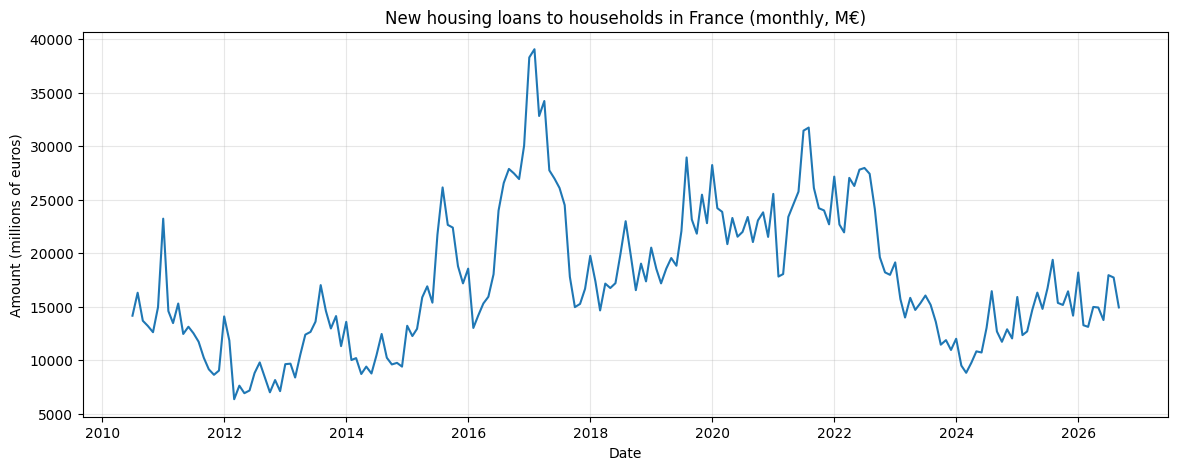

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["value"])

################# AI-generated for better visuals ##################
ax.set_title("New housing loans to households in France (monthly, M€)")
ax.set_xlabel("Date")
ax.set_ylabel("Amount (millions of euros)")
ax.grid(alpha=0.3)
####################################################################

plt.show()

The plot shows that the series does not follow a straight line. Instead, it goes through several phases. Loans rise from 2015 and reach a peak in early 2017, stay at a high level between 2019 and 2021, then fall sharply from 2022, before slowly recovering from 2024.

The peak in 2017 caught my attention, so I searched online for financial events that happened in France around that time. In 2016 and early 2017, interest rates on housing loans were at a historically low level. Many households took this opportunity to renegotiate their existing loans at a lower rate. Since this series includes renegotiated loans, this wave of renegotiations explains the very high values observed in this period (source: https://www.moneyvox.fr/credit/actualites/66706/credit-immobilier-les-compteurs-2017-se-sont-affoles). 

In the same way, the high level observed in the first half of 2022 can be explained by an anticipation effect: expecting interest rates to rise, many households rushed to take out a loan in 2022 to complete their project. The fall from the second half of 2022 then reflects the rise in interest rates, which made borrowing more expensive (source: https://www.meilleurtaux.com/credit-immobilier/actualites/2023-decembre/production-prets-immobiliers-tombe-seuil-historique.html).

No clear seasonal pattern is visible on the plot, because the large variations of the trend hide the smaller seasonal variations. This is a limit of visual examination, so the presence of seasonality will be tested statistically in the next sections.

### Train and test split
Both the band procedure and the Buys-Ballot table organise the series by year and by month. Incomplete years would bias the yearly statistics, since they would cover only part of the seasonal cycle. I therefore use the complete years from 2011 to 2025 (180 observations) as the training set, on which all the analysis will be carried out. The months from january to August 2026 (8 observations) are kept aside as a test set, to evaluate the forecasts on data the models have never seen.

In [10]:
train = df.loc["2011-01-01":"2025-12-31"]
test = df.loc["2026-01-01":"2026-08-31"]
train.shape, test.shape

((180, 1), (8, 1))

## Choosing the decomposition model
The 3 components (T, S and R) can be combined in 2 ways : in an additive model, X(t) = T(t) + S(t) + R(t), the seasonal variations have a constant size, in a multiplicative model, X(t) = T(t) × S(t) × R(t), they grow with the level of the series. To determine which model fits our series, I first use the visual band method, and then confirm the result with the Buys-Ballot test.

#### Band method

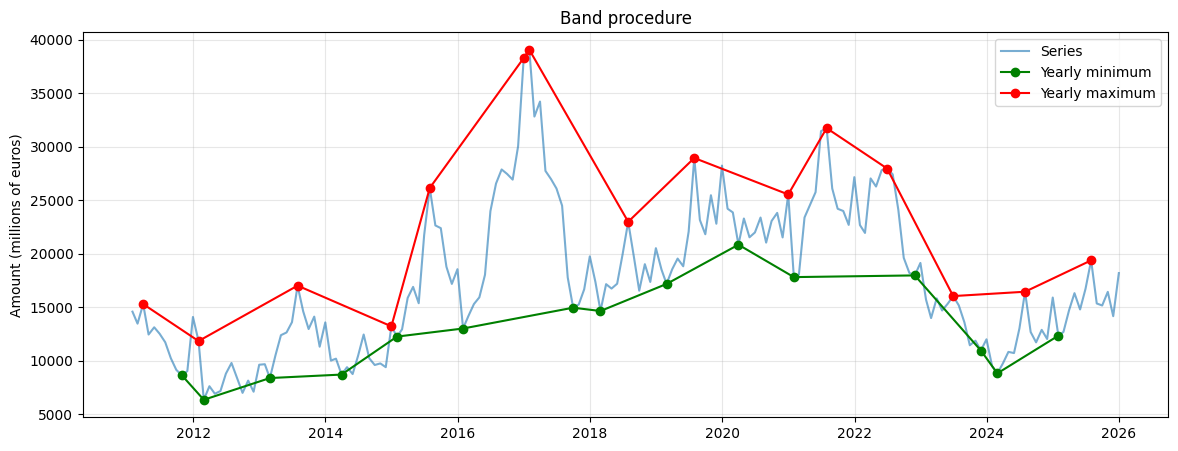

In [11]:
min_dates = train.groupby(train.index.year)["value"].idxmin()
max_dates = train.groupby(train.index.year)["value"].idxmax()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["value"], label="Series", alpha=0.6)

########################## AI-generated for better visuals and analysis ####################
ax.plot(min_dates, train.loc[min_dates, "value"], "o-", color="green", label="Yearly minimum")
ax.plot(max_dates, train.loc[max_dates, "value"], "o-", color="red", label="Yearly maximum")
ax.set_title("Band procedure")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
#############################################################################################

ax.grid(alpha=0.3)
plt.show()

The two curves are not parallel. The band is narrow when the series is low, as in 2012-2014 and 2023-2025, and much wider when the series is high, as in 2016-2017 and 2021. The size of the variations seems to grow with the level of the series, which suggests a multiplicative model. However, part of this width is caused by trend movements within the year, such as the 2016- 2017 wave of renegotiations, and not only by seasonality. This result therefore needs to be confirmed with the Buys-Ballot test.

### Buys ballot test
The Buys-Ballot test checks whether there is a linear relationship between the yearly mean and the yearly standard deviation of the series: sigma(i) = alpha + beta·mean(i) + epsolion(i). If beta is not significantly different from 0, the model is additive. If beta is significantly different from 0, the model is multiplicative.

H0: beta = 0 (no relationship, additive model). H1: beta ≠ 0 (multiplicative model). The significance level is 5%.

In [12]:
import statsmodels.api as sm

yearly = train.groupby(train.index.year)["value"].agg(["mean", "std"]) #yearly mean and std


In [13]:
# srd = alpha + beta * mean
X = sm.add_constant(yearly["mean"])
model = sm.OLS(yearly["std"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    std   R-squared:                       0.465
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     11.28
Date:                Thu, 15 Oct 2026   Prob (F-statistic):            0.00513
Time:                        16:29:02   Log-Likelihood:                -130.89
No. Observations:                  15   AIC:                             265.8
Df Residuals:                      13   BIC:                             267.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1063.3807   1365.079     -0.779      0.4

Beta is equal to 0.25, with a p-value of 0.005, below 0.05, The yearly mean has a significant effect on the yearly standard deviation. Alpha is not significant (p-value = 0.45), so the standard deviation is roughly proportional to the mean. This confirms the band procedure: the model is multiplicative.

From a business point of view, I initially found this result difficult to interpret, so I used AI to help me understand its practical meaning. In a multiplicative model, seasonal effects are percentages, not fixed amounts. For example, if a given month is always 10% below the yearly average, this represents a drop of about 2500 million euros when the average is 25 000 million, but only 1000 million when the average is 10 000 million. For a bank, this means that seasonal planning, such as sales targets or refinancing needs, should be adjusted in proportion to the level of the market rather than with fixed amounts.

## Detecting the seasonal component
After choosing the decomposition model, the next step is to check whether the series contains a seasonal component. Seasonality means that some months are systematically higher or lower than others, every year. To detect it, I use three tools from the course: the Buys-Ballot table, the sorted Buys-Ballot table, and an ANOVA test.
### Buys Ballot table


In [14]:
bb = train.pivot_table(index=train.index.year, columns=train.index.month, values="value")
bb.index.name = "Year"
bb.columns.name = "Month"
bb.round(0).style.background_gradient(axis=1)

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2011,14580.000000,13459.000000,15288.000000,12442.000000,13118.000000,12513.000000,11717.000000,10222.000000,9140.000000,8624.000000,9020.000000,14081.000000
2012,11831.000000,6341.000000,7608.000000,6905.000000,7158.000000,8784.000000,9782.000000,8360.000000,6987.000000,8133.000000,7095.000000,9618.000000
2013,9665.000000,8372.000000,10509.000000,12379.000000,12634.000000,13595.000000,17011.000000,14605.000000,12955.000000,14115.000000,11303.000000,13577.000000
2014,10004.000000,10184.000000,8698.000000,9390.000000,8746.000000,10446.000000,12442.000000,10219.000000,9593.000000,9740.000000,9389.000000,13207.000000
2015,12247.000000,12924.000000,15864.000000,16895.000000,15367.000000,21720.000000,26142.000000,22640.000000,22385.000000,18781.000000,17173.000000,18549.000000
2016,13004.000000,14154.000000,15292.000000,15919.000000,18022.000000,23978.000000,26555.000000,27872.000000,27456.000000,26923.000000,30054.000000,38294.000000
2017,39062.000000,32818.000000,34221.000000,27738.000000,26965.000000,26092.000000,24486.000000,17781.000000,14950.000000,15251.000000,16668.000000,19749.000000
2018,17352.000000,14640.000000,17150.000000,16737.000000,17191.000000,19928.000000,22982.000000,19754.000000,16538.000000,19018.000000,17357.000000,20515.000000
2019,18514.000000,17171.000000,18542.000000,19541.000000,18821.000000,22068.000000,28944.000000,23149.000000,21817.000000,25462.000000,22800.000000,28234.000000


July is often the highest month and june is often high too, while february and march are often among the lowest. This matches the market bcause households tend to buy in spring to move in before the school year. Some years break this pattern (2017, 2020, 2023), because the trend within the year (renegotiations, lockdown, rising rates) hides the seasonality.

### Sorted Buys-Ballot table
The sorted Buys-Ballot table ranks the months of each year from the highest to the lowest value. 

In [15]:
import calendar
######################### AI-generated ##########################################
sorted_bb = bb.apply(lambda row: row.sort_values(ascending=False).index, axis=1, result_type="expand")
sorted_bb = sorted_bb.apply(lambda col: col.map(lambda m: calendar.month_abbr[m]))
sorted_bb.columns = [f"Rank {i}" for i in range(1, 13)]
sorted_bb
###################################################################################

,Rank 1,Rank 2,Rank 3,Rank 4,Rank 5,Rank 6,Rank 7,Rank 8,Rank 9,Rank 10,Rank 11,Rank 12
Year,,,,,,,,,,,,
2011,Mar,Jan,Dec,Feb,May,Jun,Apr,Jul,Aug,Sep,Nov,Oct
2012,Jan,Jul,Dec,Jun,Aug,Oct,Mar,May,Nov,Sep,Apr,Feb
2013,Jul,Aug,Oct,Jun,Dec,Sep,May,Apr,Nov,Mar,Jan,Feb
2014,Dec,Jul,Jun,Aug,Feb,Jan,Oct,Sep,Apr,Nov,May,Mar
2015,Jul,Aug,Sep,Jun,Oct,Dec,Nov,Apr,Mar,May,Feb,Jan
2016,Dec,Nov,Aug,Sep,Oct,Jul,Jun,May,Apr,Mar,Feb,Jan
2017,Jan,Mar,Feb,Apr,May,Jun,Jul,Dec,Aug,Nov,Oct,Sep
2018,Jul,Dec,Jun,Aug,Oct,Nov,Jan,May,Mar,Apr,Sep,Feb
2019,Jul,Dec,Oct,Aug,Nov,Jun,Sep,Apr,May,Mar,Jan,Feb


The sorted table confirms what we saw in the Buys-Ballot table: July ranks first in 7 years out of 15, and january or february ranks last in 9 years out of 15. It also shows a second peak in december, which is often first or second. However, the middle ranks change a lot from one year to another, so the seasonality is not completely regular.

### ANOVA Test 
To confirm the presence of seasonality statistically, I use the variance analysis of the Buys-Ballot table. It splits the total variability of the series into a seasonal part (differences between months), a periodic part (differences between years) and a residual part. A Fisher test then checks whether the seasonal part is significant.

Reminder
H0: there is no seasonal effect (all months have the same mean).
H1: at least one month has a different mean.
The significance level is 5%.

In [16]:
######################################## AI-generated##################################
import numpy as np
from scipy.stats import f

P, S = bb.shape        # P = 15 years, S = 12 months
grand_mean = bb.values.mean()
season_means = bb.mean(axis=0)   # mean of each month
period_means = bb.mean(axis=1)   # mean of each year

# Sums of squares (course formulas)
Ss = P * ((season_means - grand_mean) ** 2).sum()
Sp = S * ((period_means - grand_mean) ** 2).sum()
residuals = bb.values - period_means.values[:, None] - season_means.values[None, :] + grand_mean
Sr = (residuals ** 2).sum()

# Degrees of freedom and variances
df_s, df_p, df_r = S - 1, P - 1, (P - 1) * (S - 1)
Vs, Vp, Vr = Ss / df_s, Sp / df_p, Sr / df_r

# Fisher tests
Fs, Fp = Vs / Vr, Vp / Vr
anova = pd.DataFrame({
    "Sum of squares": [Ss, Sp, Sr],
    "df": [df_s, df_p, df_r],
    "Variance": [Vs, Vp, Vr],
    "F": [Fs, Fp, None],
    "F critical (5%)": [f.ppf(0.95, df_s, df_r), f.ppf(0.95, df_p, df_r), None],
    "p-value": [f.sf(Fs, df_s, df_r), f.sf(Fp, df_p, df_r), None],
}, index=["Seasonal", "Periodic", "Residual"])
anova

,Sum of squares,df,Variance,F,F critical (5%),p-value
Seasonal,4.330830e+08,11,3.937119e+07,2.949536,1.851296,1.430264e-03
Periodic,5.539492e+09,14,3.956780e+08,29.642659,1.756489,1.155026e-36
Residual,2.055633e+09,154,1.334826e+07,NaN,NaN,NaN


The F statistic of the seasonal effect (2.95) is higher than the critical value (1.85), and the p-value (0.0014) is below 0.05. We reject H0: the series has a significant seasonal component. However, the month only explains a small part of the changes in the series (about 5%), because the seasonal sum of squares (Ss) represents only about 5% of the total sum of squares. The year explains most of it (about 69%), because the differences between yearly averages are much larger than the differences between monthly averages.

From a business point of view, this means that the month of the year has a real but limited impact on housing loan production. Interest rates and market cycles matter much more than the calendar.

### Seasonal coefficiant
The ANOVA confirmed that the series has a significant seasonal component. The next step is to measure it with seasonal coefficients: one coefficient per month, showing how much this month is above or below an average month. Since the model is multiplicative, a coefficient of 1.10 means that the month is 10% above average, and 0.90 means 10% below.

As seen in class, I first estimate the trend with a centered moving average over 12 months (CMA), which smooths out the seasonal variations. Dividing the series by this moving average removes the trend and leaves the seasonal and residual parts. The average of these ratios for each month gives the provisional coefficients. Finally, following the conservation principle, the coefficients are normalised so that their average is equal to 1.

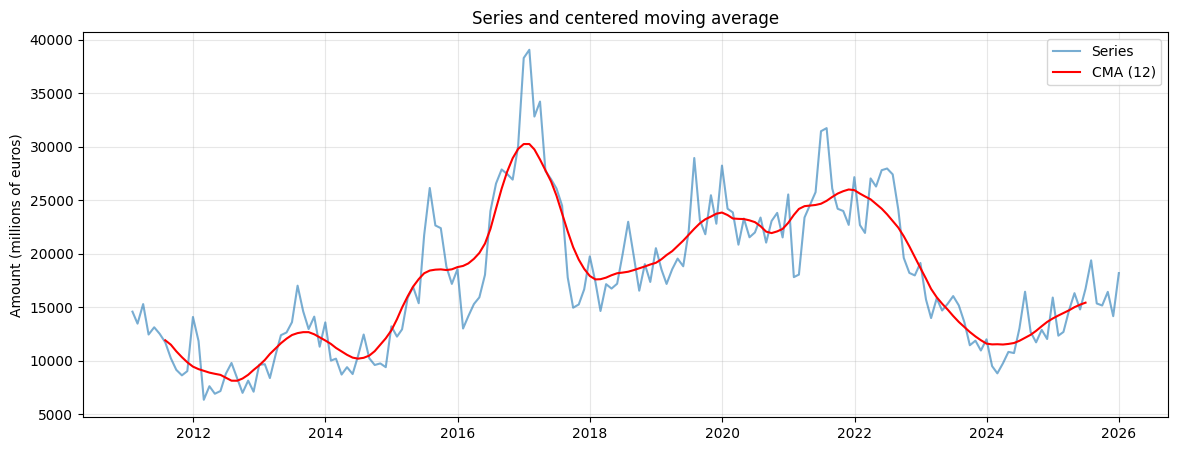

In [17]:
#CMA
# course method: 13 values,the first and last weighted by 1/2
weights = np.array([0.5] + [1] * 11 + [0.5]) / 12
train_cma = train["value"].rolling(13, center=True).apply(lambda x: np.dot(x, weights))
###################### AI-generated ################################
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["value"], label="Series", alpha=0.6)
ax.plot(train.index, train_cma, color="red", label="CMA (12)")
ax.set_title("Series and centered moving average")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
####################################################################

In [18]:
#seasonal coeff
# ratio of the series to its moving average toremove the trend)
ratios = train["value"] / train_cma

#provisional coefficients: average ratio of each month
provisional = ratios.groupby(ratios.index.month).mean()
#conservation principle  : the average must be equal to 1
print("Average of provisional coefficients:", provisional.mean())
seasonal_coefs = provisional / provisional.mean()
coefs_table = pd.DataFrame({"Coefficient": seasonal_coefs.round(3)})
coefs_table.index = [calendar.month_abbr[m] for m in coefs_table.index]
coefs_table

Average of provisional coefficients: 0.9900655725199975


,Coefficient
Jan,0.949
Feb,0.860
Mar,0.954
Apr,0.971
May,0.963
Jun,1.104
Jul,1.213
Aug,1.035
Sep,0.942
Oct,0.967


The coefficients had an average of 0.990, so they were normalised to 1 . July (+21%), december (+13%) and june (+10%) are the strongest months, while february (−14%) and november (−9%) are the weakest. For a bank, this means more loan activity in early summer and december,which helps the bank plan its sales goals and how many advisers it needs each month

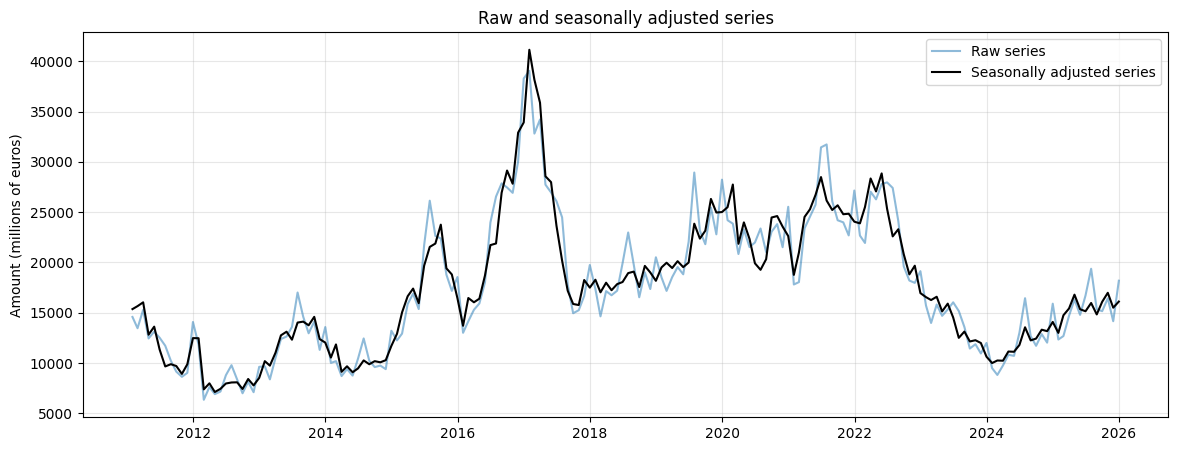

In [19]:
#seasonal adjustment (cf. TSA PDF course sent by Teams)
month_coefs = train.index.month.map(seasonal_coefs)
train_sa = train["value"] / month_coefs
######################### IA-generated######################
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["value"], label="Raw series", alpha=0.5)
ax.plot(train.index, train_sa, color="black", label="Seasonally adjusted series")
ax.set_title("Raw and seasonally adjusted series")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
###########################################################

The seasonally adjusted series is very close to the original serie, which is consistent with the ANOVA : the seasonal effect is small compared to the trend. 
Removing it mainly smooths the small peaks and drops that come back every year, such as the july peaks. 
The peak of early 2017 is even higher after adjustment: since anuary is usually a weak month, this high value in january is even more special, which confirms that it comes from the renegotiation wave and not from the calendar

### Detecting the trend
As seen in class, the trend is detected with the same tools as the seasonality. The plot already suggested a strong trend. To confirm it statistically, I use the periodic (row) effect test from the variance analysis of the Buys-Ballot table, which checks whether the yearly means are significantly different.

In [20]:
anova.loc[["Periodic"]]

,Sum of squares,df,Variance,F,F critical (5%),p-value
Periodic,5.539492e+09,14,3.956780e+08,29.642659,1.756489,1.155026e-36


F (29.6) is much higher than the critical value (1.76) and the p-value is close to 0, so we reject H0: the series has a significant trend, which explains about 69% of the total variability.

### Extracting the trend
#### Linear regression
The first way to extract a trend is to model it with a regression. In the case of a linear trend, the model is X(t) = alpha + beta*t + epsilon(t), where t is time. I apply it to the seasonally adjusted series, so that the seasonality does not disturb the estimation of the trend.

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.082
Model:                            OLS   Adj. R-squared:                  0.077
Method:                 Least Squares   F-statistic:                     15.93
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           9.61e-05
Time:                        16:29:04   Log-Likelihood:                -1829.8
No. Observations:                 180   AIC:                             3664.
Df Residuals:                     178   BIC:                             3670.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.419e+04    946.777     14.988      0.0

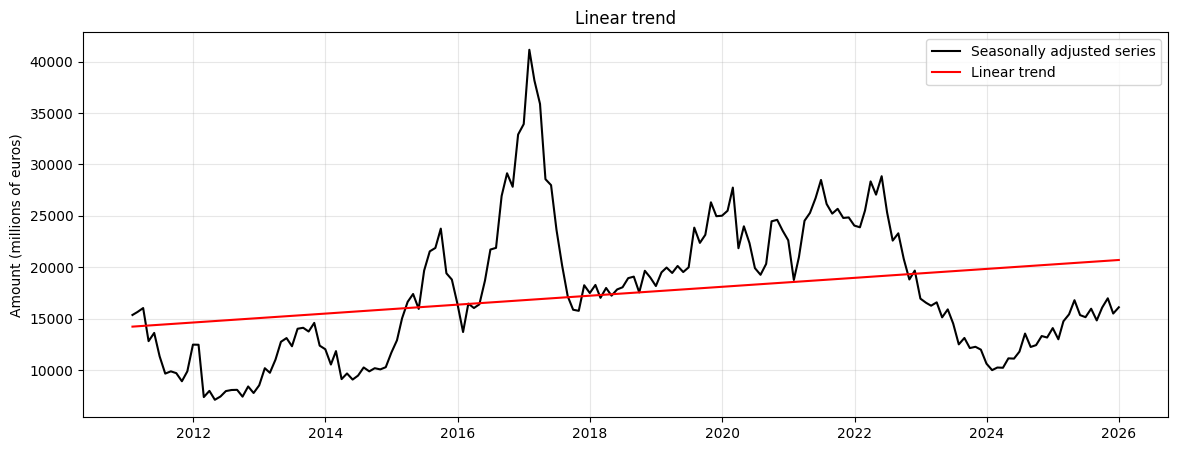

In [21]:
t = np.arange(1, len(train_sa) + 1)

X = sm.add_constant(t)
trend_model = sm.OLS(train_sa.values, X).fit()
print(trend_model.summary())

################# AI-generated#####################################
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train_sa, label="Seasonally adjusted series", color="black")
ax.plot(train.index, trend_model.fittedvalues, label="Linear trend", color="red")
ax.set_title("Linear trend")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
###################################################################

Beta (36.2) is significant, but the R² is only 0.08 The linear trend explains only 8% of the variations of the series. The plot confirms that the line does not follow the successive phases of rise and fall. The trend is therefore not linear and cannot be modelled by a simple regression. As sdiscussed during CM, it should instead be treated as a random trend and estimated with filtering methods.

### Centered moving average (CMA)
Since the trend is not linear, it is treated as a random trend and estimated with filtering methods, as discusse in class. The centered mooving average over 12 months (CMA), computed in the seasonal section, is a first estimate of the trend: it smooths out the seasonal and random variations and follows the long-term movements of the series.

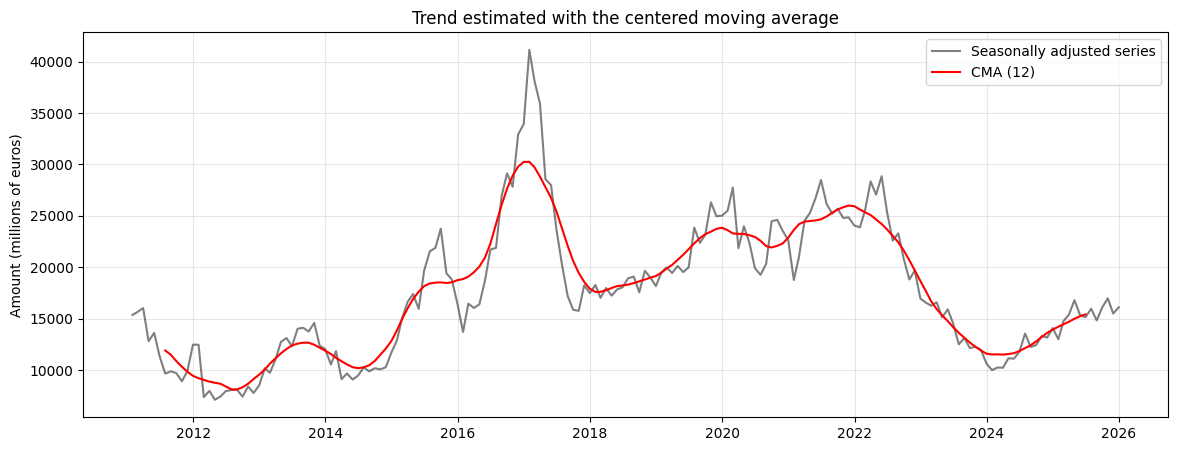

In [23]:
#################### AI-generated ###############################
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train_sa, label="Seasonally adjusted series", color="black", alpha=0.5)
ax.plot(train.index, train_cma, label="CMA (12)", color="red")
ax.set_title("Trend estimated with the centered moving average")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
####################################################################

the CMA follows all the phases of the series

### Double exponentiel smoothing
Since the CMA cannot forecast bc it uses future values that do not exist, I use double exponential Smoothing (DES). It treats the trend as locally linear, it computes an intercept and a slope that change over time, and the forecast is slope × h + intercept, where h is the horizon. It depends on a parameter λ between 0 and 1, which I choose by minimising the MSE.

In [27]:
#########################AI-generated but using course formulas#########################
def des(x, lam):
    """Double exponential smoothing, following the course formulas.
    Returns the in-sample forecasts and the last slope (a) and intercept (b)."""
    x = np.asarray(x)
    n = len(x)
    s1 = np.zeros(n + 1)   # first smoothing
    s2 = np.zeros(n + 1)   # second smoothing
    s1[0] = s2[0] = x[0]   # initialisation with the first value

    for t in range(1, n + 1):
        s1[t] = lam * x[t - 1] + (1 - lam) * s1[t - 1]
        s2[t] = lam * s1[t] + (1 - lam) * s2[t - 1]

    b = 2 * s1 - s2                        # adaptive intercept
    a = (s1 - s2) * lam / (1 - lam)        # adaptive slope
    forecasts = a + b                      # in-sample forecasts
    return forecasts, a[n], b[n]


Best lambda: 0.57 | MSE: 4119218.0


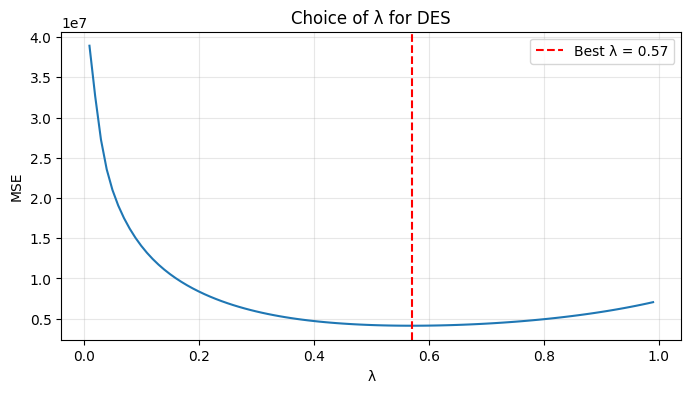

In [28]:
x = train_sa.values
lambdas = np.arange(0.01, 1.00, 0.01)
mse_list = []

for lam in lambdas:
    forecasts, _, _ = des(x, lam)
    errors = x[1:] - forecasts[1:-1]   # compare F(t) with X(t), for t = 2..n
    mse_list.append(np.mean(errors ** 2))

best_lam = lambdas[np.argmin(mse_list)]
print("Best lambda:", round(best_lam, 2), "| MSE:", round(min(mse_list), 0))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lambdas, mse_list)
ax.axvline(best_lam, color="red", linestyle="--", label=f"Best λ = {best_lam:.2f}")
ax.set_xlabel("λ")
ax.set_ylabel("MSE")
ax.set_title("Choice of λ for DES")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

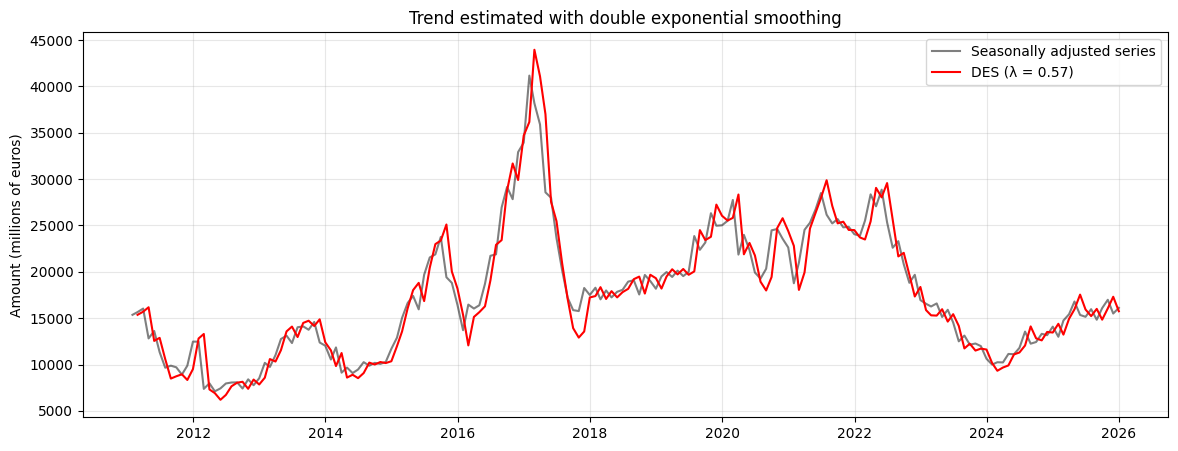

Last slope a: 29.3 | Last intercept b: 16042.5


In [29]:
des_fit, a_last, b_last = des(x, best_lam)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, x, label="Seasonally adjusted series", color="black", alpha=0.5)
ax.plot(train.index[1:], des_fit[1:-1], label=f"DES (λ = {best_lam:.2f})", color="red")
ax.set_title("Trend estimated with double exponential smoothing")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Last slope a:", round(a_last, 1), "| Last intercept b:", round(b_last, 1))
###########################################################################################

The best lambda is 0.57, which means that DES gives a lot of weight to recent values: the market reacts quickly to current conditions such as interest rates. The MSE curve is quite flat between 0.4 and 0.8, so the exact choice of λ in this range has little impact. The MSE is about 4.1 million, which gives an RMSE of about 2,030 million euro. The smoothed series follows the data closely, with a one-month delay, but it overshoots sharp turning points such as the 2017 peak.

### Forecasting with Recomposition
The last step of the decomposition method is to recombine the components to forecast the series. Since the model is multiplicative, the forecast is the trend forecast multiplied by the seasonal coefficient of the month: X(n+h) = T(n+h) * S(month). The trend is forcast with DES, and the seasonal coefficients are those computed earlier. The forecasts are then compared with the real values from january to august 2026, using the MSE, RMSE and MAPE.

In [30]:
h = np.arange(1, len(test) + 1) #horizon 1 to 8
trend_forecast = a_last * h + b_last
test_coefs = test.index.month.map(seasonal_coefs).values
decomp_forecast = trend_forecast * test_coefs   #bc multiplicative
results = pd.DataFrame({
    "Actual": test["value"].values,
    "Trend forecast": trend_forecast.round(0),
    "Seasonal coef": test_coefs.round(3),
    "Forecast": decomp_forecast.round(0),
}, index=test.index.strftime("%b %Y"))
results

,Actual,Trend forecast,Seasonal coef,Forecast
date,,,,
Jan 2026,13258.0,16072.0,0.949,15255.0
Feb 2026,13107.0,16101.0,0.860,13843.0
Mar 2026,14968.0,16130.0,0.954,15381.0
Apr 2026,14915.0,16160.0,0.971,15690.0
May 2026,13742.0,16189.0,0.963,15597.0
Jun 2026,17938.0,16218.0,1.104,17900.0
Jul 2026,17718.0,16248.0,1.213,19713.0
Aug 2026,14925.0,16277.0,1.035,16842.0


In [35]:
errors = test["value"].values - decomp_forecast
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)
mape = np.mean(np.abs(errors / test["value"].values)) * 100
print(f"{mse:,.0f}  {rmse:,.0f} M€   {mape:.1f}%")
scores = {"Decomposition (DES × seasonal)": {"MSE": mse, "RMSE": rmse, "MAPE (%)": mape}}

2,050,017  1,432 M€   8.3%


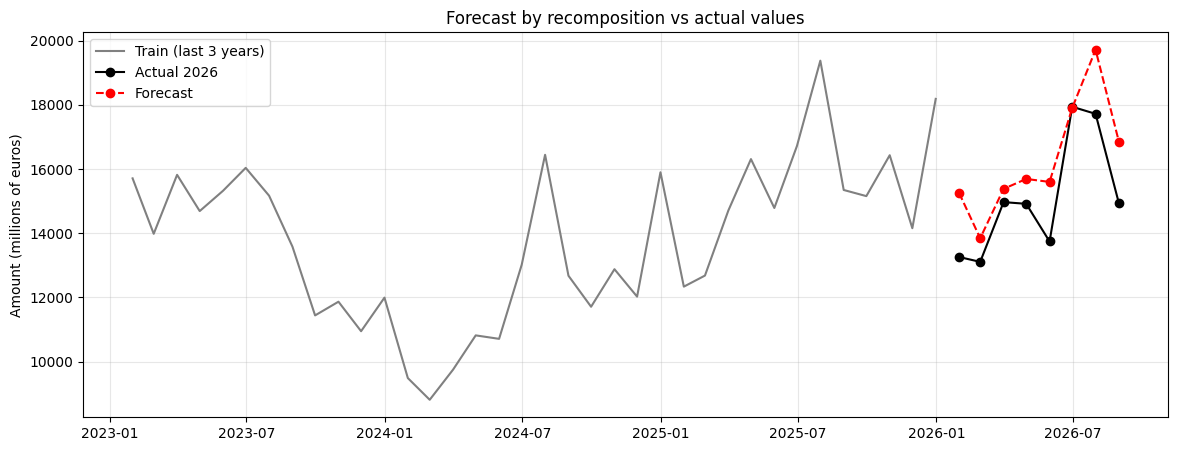

In [36]:
####################### AI-generated ##############
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-36:], train["value"][-36:], label="Train (last 3 years)", color="gray")
ax.plot(test.index, test["value"], label="Actual 2026", color="black", marker="o")
ax.plot(test.index, decomp_forecast, label="Forecast", color="red", marker="o", linestyle="--")
ax.set_title("Forecast by recomposition vs actual values")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
############################################

The forecast has a MAPE of 8.3% and an RMSE of about 1,430 million euro, which is a good result. It captures well the seasonal shape. The drop in February, the peak in june and july and the fall in august. However, it is above the actual values in 7 months out of 8, so the error mosty comes from the trend level, which is slihgtly too high. This may be because the training data ends with a high value in december 2025, and DES gives a lot of weight to recent values.

From a business point of view, this method would give a bank a reliable view of when activity goes up and down during the year, but with a slightly optimistic level.

As a conclusion, the ETS decomposition of the serieshave been done. the series has been split into its Error (residual), Trend and Seasonal components

## ARIMA model
The project requires a second forecasting method, either ARIMA or Prophet. I chose ARIMA because it is part of the course. Unlike the decomposition method, ARIMA does not split the series into components, it models each value as a function of its past values and past errors.

ARIMA(p,d, q) has three parameters: p is the number of past values used (autoregressive part), d is the number of times the series is differencied to make it stationary, and q is the number of past errors used . The method follows three steps. making the series stationary, identifying p and q, and checking the model before forecasting.

### Log transformation
ARIMA assumes a constant variance, but our series is multiplicative. Taking the log makes it additive and stabilises the variance, so I work on log(X(t)) and transform the forecasts back at the end.

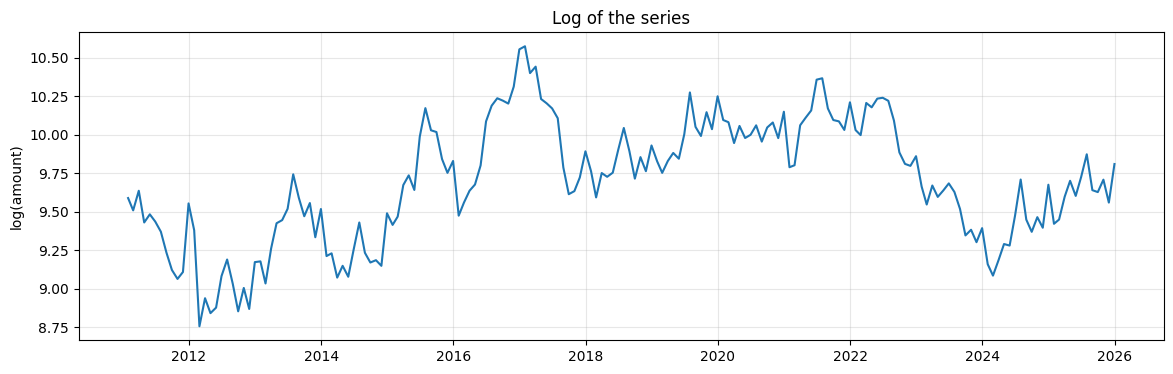

In [37]:
train_log = np.log(train["value"])

########################## AI-generated##############################
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train_log.index, train_log)
ax.set_title("Log of the series")
ax.set_ylabel("log(amount)")
ax.grid(alpha=0.3)
plt.show()
#######################################################################""

The log series keeps the same shape as the original series, but the variations are more balanced between low and high periods

### Stationnarity
ARIMA requires a stationary series: as defined in class, its mean and variance must stay constant over time, and its values must not be correlated with each other. Our series has a strong trend, so it is not stationary. To remove the trend, I difference the series (X(t) − X(t−1)). I then check stationarity in two ways: visually, and with the autocorrelation function (ACF), which measures how much each value is correlated with past values.

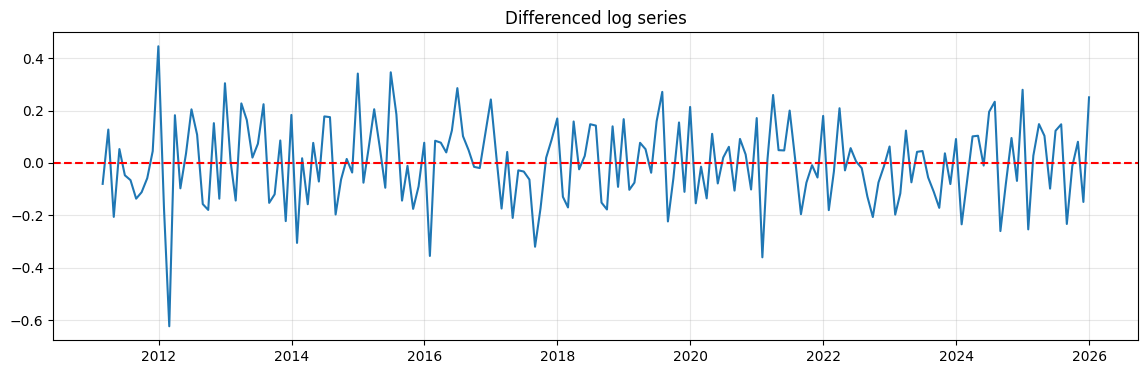

In [38]:
train_log_diff = train_log.diff().dropna()

####################### AI-generated#####################""
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train_log_diff.index, train_log_diff)
ax.axhline(0, color="red", linestyle="--")
ax.set_title("Differenced log series")
ax.grid(alpha=0.3)
plt.show()
#######################################################

After differencing, the series oscillates around 0 with no trend and stable variations, so it looks stationary. The remaining ups and downs come from seasonality and random monthly changes.

### ACF to confirm stationnarity


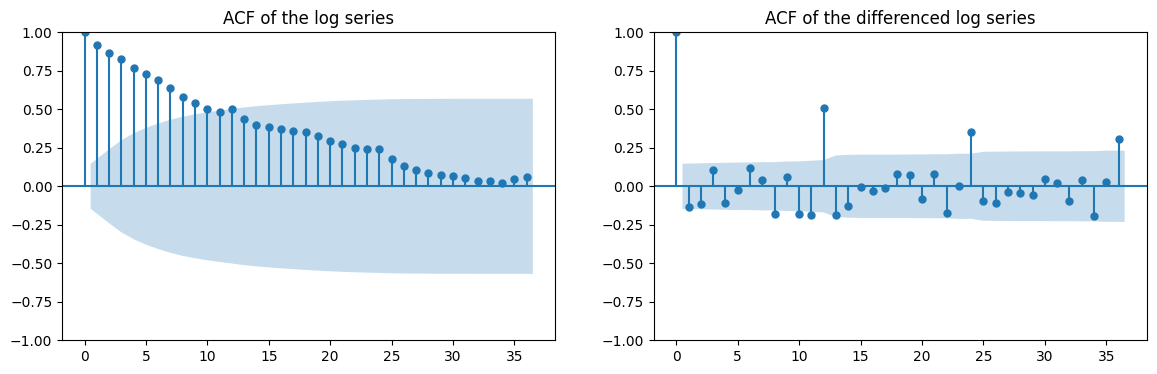

In [39]:
from statsmodels.graphics.tsaplots import plot_acf
##################### AI-generated##########################
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train_log, lags=36, ax=axes[0], title="ACF of the log series")
plot_acf(train_log_diff, lags=36, ax=axes[1], title="ACF of the differenced log series")
plt.show()
##########################################################

The ACF of the log series decreases very slowly, which confirms a trend: the series is not stationary. After differencing, the correlations quickly fall inside the confidence interval, so the series is stationary and d = 1. However, there are significant peaks at lags 12, 24 and 36, so the seasonality is still present and must be taken into account in the model.

### ARIMA on the seasonaly adjusted series
To pursue the decomposition method, I remove the seasonality with the seasonal coefficients computed earlier, apply ARIMA to the seasonally adjusted series, and multiply the forecasts by these coefficients at the end.

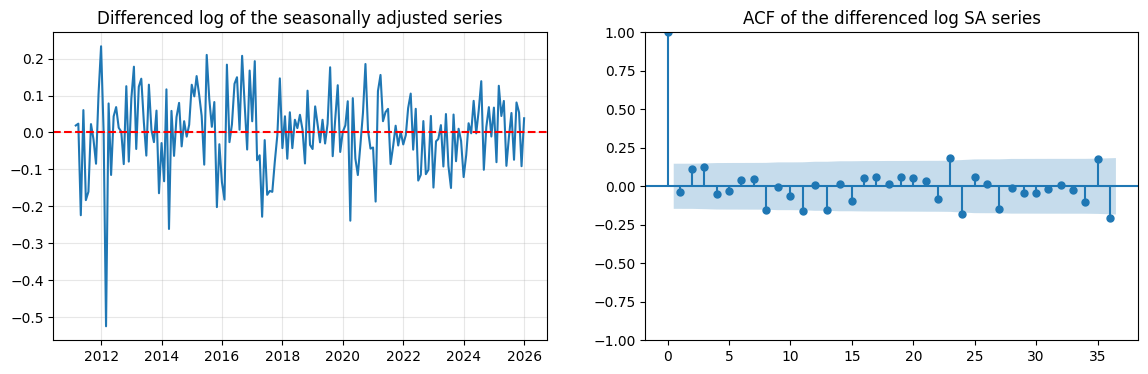

In [41]:
train_sa_log = np.log(train_sa)
train_sa_log_diff = train_sa_log.diff().dropna()

############################ AI-generated#######################""
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(train_sa_log_diff.index, train_sa_log_diff)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Differenced log of the seasonally adjusted series")
axes[0].grid(alpha=0.3)
plot_acf(train_sa_log_diff, lags=36, ax=axes[1], title="ACF of the differenced log SA series")
plt.show()
##############################################################""

After removing the seasonality, the peaks at lags 12, 24 and 36 have disappeared, which confirms that the seasonal coefficients captured the seasonal pattern well (verified with AI because couldn't understand why it disappeared at first). Almost all correlations are now inside the confidence interval, so the monthly changes depend very little on past months. The ARIMA model will therefore probably need very few parameters.

### Choice of p and q
I test all ARIMA(p, 1, q) models with p and q between 0 and 2, trained on 2011–2024, and keep the one with the lowest MSE on 2025. The 2026 test set stays untouched for the final comparison.

In [42]:
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")   # hide convergence warnings (AI adviced)

# Split the training data: 2011-2024 to fit, 2025 to validate
fit_log = train_sa_log.loc[:"2024-12-31"]
val = train_sa.loc["2025-01-01":]
############################ AI-generated#########################""
arima_results = []
for p in range(3):
    for q in range(3):
        model = ARIMA(fit_log, order=(p, 1, q)).fit()
        forecast = np.exp(model.forecast(steps=len(val)))   # back to millions of euros
        errors = val.values - forecast.values
        arima_results.append({"p": p, "q": q, "MSE (2025)": np.mean(errors ** 2)})
####################################################################""
arima_results = pd.DataFrame(arima_results).sort_values("MSE (2025)")
arima_results["MSE (2025)"] = arima_results["MSE (2025)"].round(0)
arima_results

,p,q,MSE (2025)
4,1,1,2075104.0
7,2,1,2325986.0
5,1,2,2345196.0
8,2,2,2513339.0
6,2,0,2774792.0
2,0,2,2806467.0
0,0,0,3008757.0
1,0,1,3057376.0
3,1,0,3067632.0


The best model is ARIMA(1,1,1). It clearly improves on ARIMA(0,1,0), whose MSE is 3.01 million, while more complex models do not perform better. Since the validation period only covers 12 months, this ranking should be read with some precaution.

### Forecast of 2026
I now train ARIMA(1,1,1) on the full training set (2011–2025), forecast the seasonally adjusted series for 2026, and multiply the forecasts by the seasonal coefficients to obtain the final forecasts.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6969      0.791      0.881      0.378      -0.853       2.247
ma.L1         -0.6613      0.825     -0.801      0.423      -2.279       0.956
sigma2         0.0110      0.001     13.769      0.000       0.009       0.013
MSE: 1,925,093 | RMSE: 1,387 M€ | MAPE: 8.2%


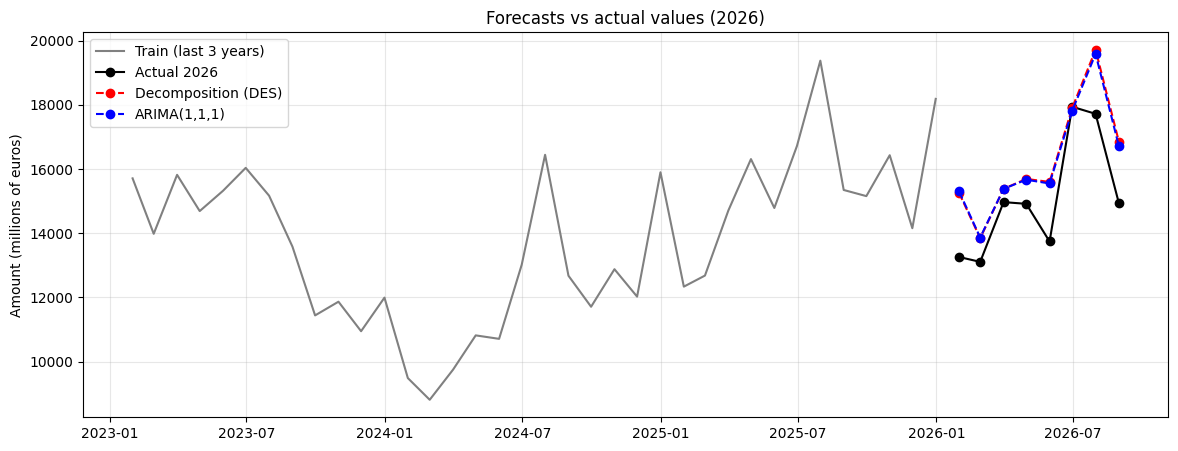

In [43]:
final_arima = ARIMA(train_sa_log, order=(1, 1, 1)).fit()
print(final_arima.summary().tables[1])

sa_forecast = np.exp(final_arima.forecast(steps=len(test))).values
arima_forecast = sa_forecast * test_coefs

#errors
errors = test["value"].values - arima_forecast
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)
mape = np.mean(np.abs(errors / test["value"].values)) * 100
print(f"MSE: {mse:,.0f} | RMSE: {rmse:,.0f} M€ | MAPE: {mape:.1f}%")
scores["ARIMA(1,1,1) × seasonal"] = {"MSE": mse, "RMSE": rmse, "MAPE (%)": mape}

############################AI-generated#############################
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-36:], train["value"][-36:], label="Train (last 3 years)", color="gray")
ax.plot(test.index, test["value"], label="Actual 2026", color="black", marker="o")
ax.plot(test.index, decomp_forecast, label="Decomposition (DES)", color="red", marker="o", linestyle="--")
ax.plot(test.index, arima_forecast, label="ARIMA(1,1,1)", color="blue", marker="o", linestyle="--")
ax.set_title("Forecasts vs actual values (2026)")
ax.set_ylabel("Amount (millions of euros)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
#######################################################################

None coefficient is significant and they almost cancel out, so the model behaves like a random walk, as the ACF suggested. ARIMA (MAPE 8.2%) is only very slightly better than the decomposition (8.3%): both use the same seasonal coefficients and overestimate 2026 by extending the level of late 2025. Past values alone cannot anticipate market shifts driven by external factors such as interest rates.

## Methodological comparison of forecasts
To compare the two forecasting methods, I use the loss functions seen in class, computed on the 2026 test set: the MSE, the RMSE (in millions of euros) and the MAPE (in percentage). The lower these values, the better the forecast.

In [44]:
comparison = pd.DataFrame(scores).T
comparison["MSE"] = comparison["MSE"].round(0)
comparison["RMSE"] = comparison["RMSE"].round(0)
comparison["MAPE (%)"] = comparison["MAPE (%)"].round(1)
comparison.sort_values("MAPE (%)")

,MSE,RMSE,MAPE (%)
"ARIMA(1,1,1) × seasonal",1925093.0,1387.0,8.2
Decomposition (DES × seasonal),2050017.0,1432.0,8.3


Both methods give good forecasts, with a MAPE close to 8%. ARIMA is very slightly better, but the difference is too small to prefer one method over the other. This is because both use the same seasonal coefficients and only differ in how they forecast the trend. Their common weakness is the trend level, which both overestimate in 2026. The decomposition method remains easier to interpret, since each component can be explained separately, which makes it more useful to present forecasts to business teams.

# Conclusion

The objective of this project was to apply the time series methods seen in class to a real dataset: the monthly amount of new housing loans granted to households in France.

The analysis showed that the series follows a multiplicative model, with a strong non-linear trend and a significant but small seasonal component. The trend is driven by interest rate cycles, such as the wave of renegotiations in 2016–2017 and the sharp decline after the rate increases of 2022. The seasonal pattern shows more activity in early summer and in December, and less in February and November.

Both forecasting methods, decomposition with DES and ARIMA, gave good and very similar results on 2026, with an error of about 8%. They correctly capture the seasonal shape of the year, but both overestimate the level of the market, because they rely only on past values.

This project has several limits. The series includes renegotiated loans, which create peaks that are not linked to new purchases. The test period only covers eight months, and the choice of the ARIMA parameters is based on a single validation year. Finally, the models do not include external factors such as interest rates, which explain most of the changes in the trend. Adding such variables would be a natural next step to improve the forecasts.

# AI-use policy

This project was carried out with the help of Claude (Anthropic). All methodological choices were mine: at each step, I followed the courses' method. The AI mainly played an execution role, applying the methodology I had chosen.

All AI-generated code is marked in the notebook between banners (##### AI-generated #####); most of it concerns plots. I also used AI to understand some results, for example why the peaks at lags 12, 24 and 36 disappeared from the ACF, and to rephrase some explanations in English, which I then reviewed and adapted.

Main prompts: “Explain why this result is ... simply”, “Write the code for this plot”, “Make this interpretation shorter”.